In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8')

In [2]:
#Step-1:Generate Toy(Dummy) Dataset

X,Y=make_blobs(n_samples=2000, n_features=2, centers=2, random_state=42,cluster_std=3)
n_features=2

In [3]:
print(X.shape,Y.shape)

(2000, 2) (2000,)


In [4]:
print(Y)

[0 0 0 ... 1 0 1]


In [5]:
#Step-2:Visualize Dataset
def visualize(X,Y):
    plt.scatter(X[:, 0], X[:, 1],c=Y,cmap='viridis')
    plt.show()

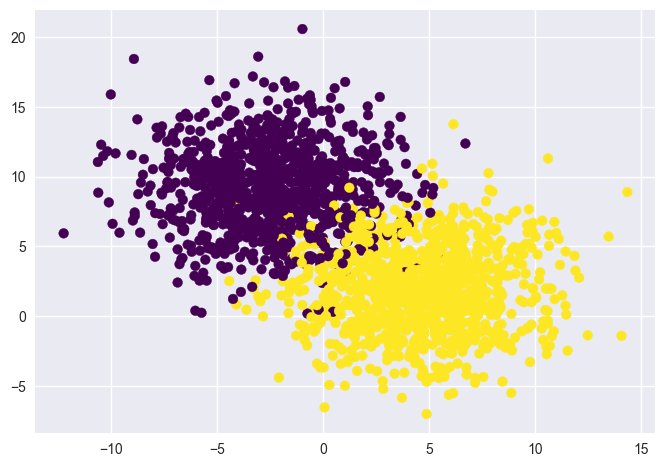

In [46]:
visualize(X,Y)

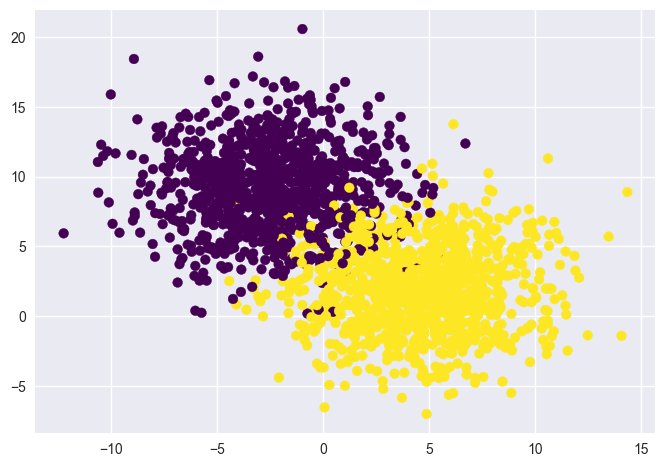

In [6]:
#After Cluster standard
visualize(X,Y)

In [7]:
#Step-3:Normalize

def normalise(X):
    u=X.mean(axis=0)
    std=X.std(axis=0)

    return (X-u)/std

In [8]:
X=normalise(X)

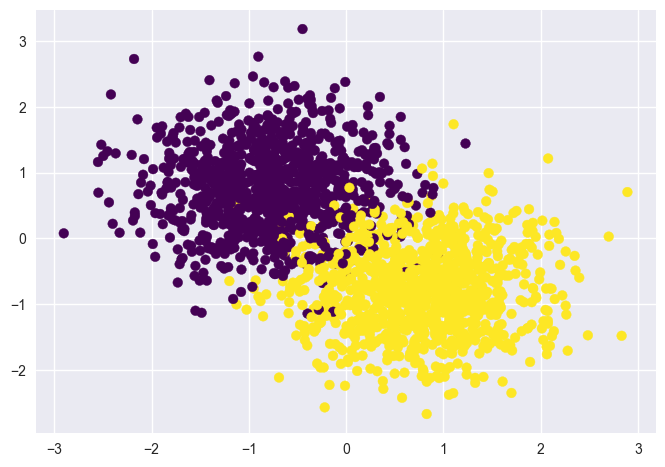

In [9]:
visualize(X,Y)

In [10]:
#Step-4:Train Test Split
XT,Xt,YT,Yt=train_test_split(X,Y,test_size=0.25,random_state=0,shuffle=False)

In [11]:
print(XT.shape,YT.shape)
print(Xt.shape,Yt.shape)

(1500, 2) (1500,)
(500, 2) (500,)


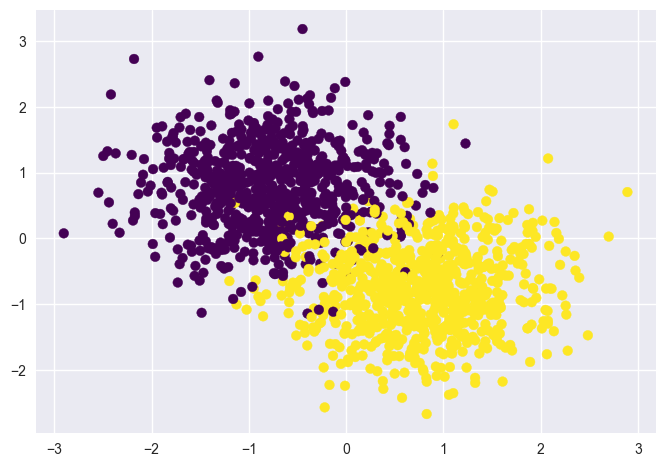

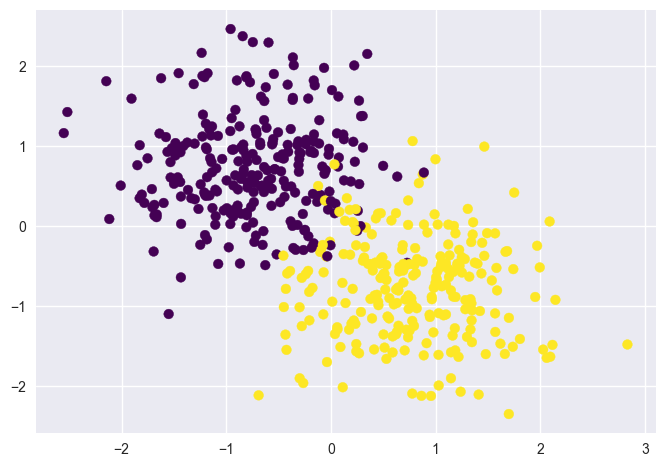

In [12]:
visualize(XT,YT)
visualize(Xt,Yt)

In [30]:
#Model
def sigmoid(z):
    return 1/(1+np.exp(-z))

def hypothesis(X,theta):
    return sigmoid(X.dot(theta))

#Binary Code ENTROPY

def error(Y,yp):

    loss=-np.mean(Y*np.log(yp) + (1-Y)*np.log(1-yp))
    return loss

def gradient(X,Y,yp):
    m=X.shape[0]
    grad=-(1/m)*np.dot(X.T,(Y-yp))
    return grad

def train(X,Y,MAXITERS=100,lr=0.1):

    #Randomly Initialized theta
    theta=np.random.randn(n_features+1,1)
    error_list=[]

    for i in range(MAXITERS):
        yp=hypothesis(X,theta)
        e=error(Y,yp)
        error_list.append(e)
        grad=gradient(X,Y,yp)
        theta=theta-lr*grad

    plt.plot(error_list)
    return theta

def predict(X,theta):
    h=hypothesis(X,theta)
    preds =np.zeros((X.shape[0],1))
    preds[h >= 0.5]=1

    return preds

def accuracy(X,Y,theta):
    preds=predict(X,theta)
    return ((Y==preds).sum())/Y.shape[0]*100

In [15]:
theta=np.random.randn(n_features+1,1)

In [16]:
theta

array([[-0.86603633],
       [-0.08256481],
       [-1.2040626 ]])

In [17]:
def addExtraCol(X):
    if X.shape[1]==n_features:
        ones=np.ones((X.shape[0],1))
        X=np.hstack((ones,X))
    return X

In [18]:
XT=addExtraCol(XT)
print(XT)

[[ 1.         -1.43211741  0.65078613]
 [ 1.         -0.47100516  0.87372191]
 [ 1.         -0.40182883  2.1275269 ]
 ...
 [ 1.          0.02390726  0.74454457]
 [ 1.         -0.35936993  0.18771848]
 [ 1.          1.09360417 -1.10077065]]


In [19]:
Xt=addExtraCol(Xt)
print(Xt)

[[ 1.         -1.17860853  1.9119189 ]
 [ 1.          0.70445084 -1.55536144]
 [ 1.          0.39063944 -0.10336496]
 ...
 [ 1.          1.96970601 -0.24632291]
 [ 1.         -0.80805197 -0.01411826]
 [ 1.          0.83964924  0.53655099]]


In [20]:
print(XT.shape)

(1500, 3)


In [21]:
print(YT.shape)

(1500,)


In [22]:
YT=YT.reshape(-1,1)
Yt=Yt.reshape(-1,1)

In [23]:
print(YT.shape)
print(Yt.shape)

(1500, 1)
(500, 1)


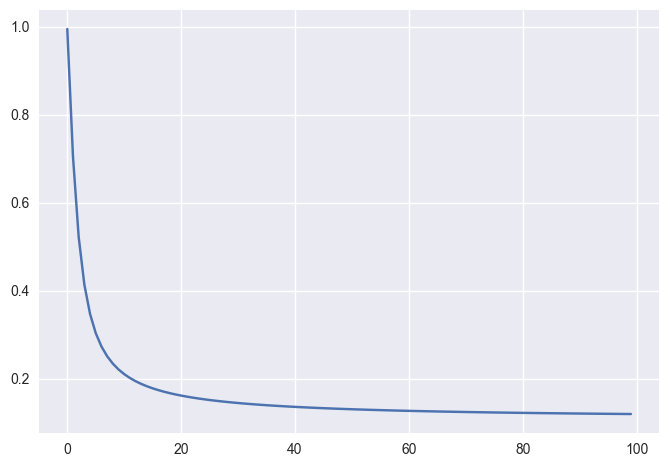

In [24]:
theta=train(XT,YT,MAXITERS=100,lr=0.8)

In [25]:
theta

array([[ 0.04060812],
       [ 2.63754275],
       [-2.97186425]])

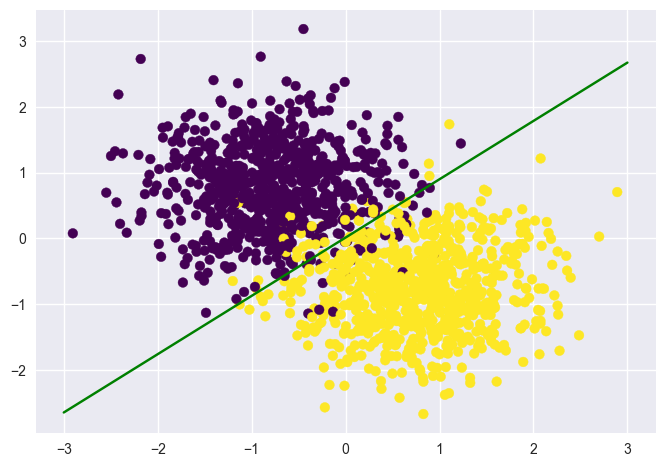

In [26]:
plt.scatter(XT[:,1],XT[:,2],c=YT,cmap='viridis')
x1=np.linspace(-3,3,6)
x2=-(theta[0][0]+theta[1][0]*x1)/ theta[2][0]
plt.plot(x1,x2,color='green')
plt.show()

In [27]:
#Prediction

hypothesis(Xt,theta)

array([[1.58438484e-04],
       [9.98529895e-01],
       [7.98689374e-01],
       [3.82529684e-02],
       [3.71298209e-02],
       [2.17349013e-01],
       [3.00344041e-01],
       [9.98666180e-01],
       [9.99955799e-01],
       [1.44164121e-02],
       [9.98805791e-01],
       [5.09564251e-02],
       [7.62303385e-05],
       [9.99837267e-01],
       [9.93739028e-01],
       [1.34343368e-02],
       [6.77561944e-03],
       [6.93859657e-01],
       [2.08534920e-02],
       [1.37998410e-01],
       [5.74478586e-02],
       [9.89399164e-01],
       [9.91404976e-01],
       [9.90064501e-01],
       [9.96716318e-01],
       [8.93968875e-01],
       [1.91851311e-02],
       [2.49224266e-02],
       [9.92049017e-01],
       [1.35976467e-02],
       [9.97930820e-01],
       [9.05655936e-02],
       [3.38861270e-03],
       [6.46275544e-02],
       [9.01587255e-01],
       [9.84150934e-02],
       [1.07112432e-02],
       [2.10959114e-03],
       [9.99922679e-01],
       [1.02956229e-01],


In [32]:
preds=predict(Xt,theta)

In [33]:
accuracy(XT,YT,theta)

95.8

In [34]:
accuracy(Xt,Yt,theta)

96.2

In [35]:
#Sklearn Version
from sklearn.linear_model import LogisticRegression

In [36]:
#Create
X,Y=make_blobs(n_samples=2000, n_features=2, centers=2, random_state=42,cluster_std=3)
model=LogisticRegression()

In [37]:
#Training
model.fit(X,Y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [38]:
#Predictions
model.predict(X)

array([0, 0, 0, ..., 1, 0, 1])

In [39]:
#Scoring
model.score(X,Y)

0.96

In [54]:
#Multiclass Classification:One VS Rest
from sklearn.multiclass import OneVsRestClassifier
X,Y=make_blobs(n_samples=2000, n_features=5, centers=3, random_state=42,cluster_std=3)

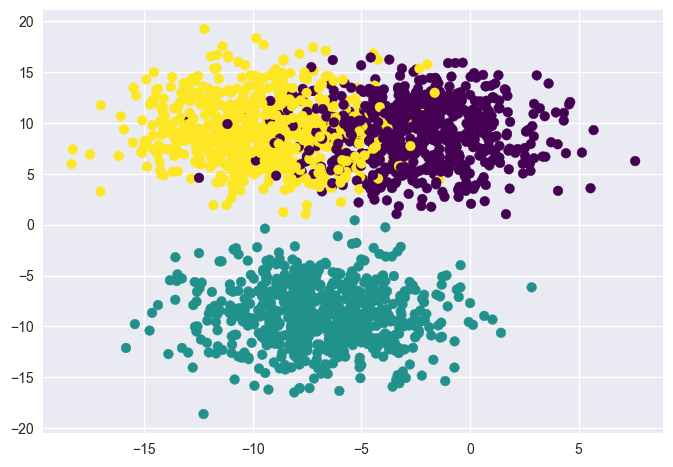

In [60]:
plt.scatter(X[:,0],X[:,1],c=Y,cmap='viridis')
plt.show()

In [59]:
print(np.unique(Y,return_counts=True))

(array([0, 1, 2]), array([667, 667, 666], dtype=int64))


In [50]:
OneVsRestClassifier(LogisticRegression())

,estimator,LogisticRegression()
,n_jobs,None
,verbose,0
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None


In [56]:
model.fit(X,Y)

C:\Users\vaibh\OneDrive\Documents\COMPUTER VISION\.venv\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'ovr'


In [57]:
model.predict(X)

array([0, 2, 0, ..., 2, 2, 2])

In [58]:
model.score(X,Y)

0.976